In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv("/content/sample_data/Titanic-Dataset.csv")
df = df[['Fare', 'Pclass', 'Age', 'SibSp', 'Parch']]
df['Age'] = df['Age'].fillna(df['Age'].median())
df = df[df['Fare'] > 0]

In [ ]:
X_simple = df[['Pclass']]
y = df['Fare']
X_tr, X_te, y_tr, y_te = train_test_split(X_simple, y, test_size=0.2, random_state=42)
model_simple = LinearRegression().fit(X_tr, y_tr)
pred_simple = model_simple.predict(X_te)
print("SIMPLE Regression -- Intercept:", round(model_simple.intercept_, 2))
print("SIMPLE Regression -- Slope:", round(model_simple.coef_[0], 2))
print("SIMPLE Regression -- R2:", round(r2_score(y_te, pred_simple), 3))
print("SIMPLE Regression -- RMSE:", round(np.sqrt(mean_squared_error(y_te, pred_simple)), 2))

SIMPLE Regression -- Intercept: 112.38
SIMPLE Regression -- Slope: -34.23
SIMPLE Regression -- R2: 0.371
SIMPLE Regression -- RMSE: 35.68


In [ ]:
X_multi = df[['Pclass', 'Age', 'SibSp', 'Parch']]
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(X_multi, y, test_size=0.2, random_state=42)
model_multi = LinearRegression().fit(X_tr2, y_tr2)
pred_multi = model_multi.predict(X_te2)
print("MULTI Regression -- Intercept:", round(model_multi.intercept_, 2))
for name, coef in zip(X_multi.columns, model_multi.coef_):
    print("MULTI Regression -- :", name, round(coef, 2))
print("MULTI Regression -- R2:", round(r2_score(y_te2, pred_multi), 3))
print("MULTI Regression -- RMSE:", round(np.sqrt(mean_squared_error(y_te2, pred_multi)), 2))

MULTI Regression -- Intercept: 112.3
MULTI Regression -- : Pclass -35.72
MULTI Regression -- : Age -0.12
MULTI Regression -- : SibSp 5.38
MULTI Regression -- : Parch 10.09
MULTI Regression -- R2: 0.462
MULTI Regression -- RMSE: 33.0


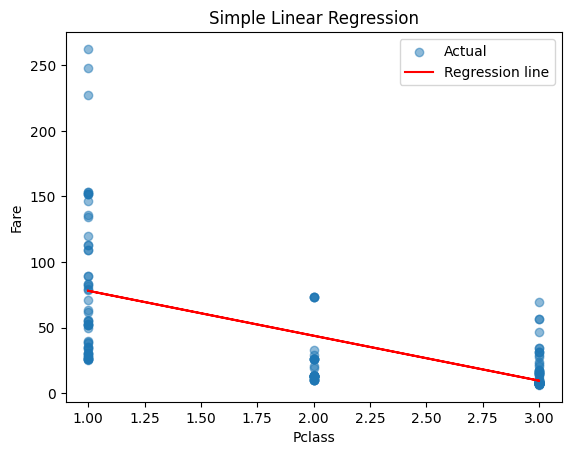

In [ ]:
plt.scatter(X_te, y_te, alpha=0.5, label='Actual')
plt.plot(X_te, pred_simple, color='red', label='Regression line')
plt.xlabel('Pclass');
plt.ylabel('Fare');
plt.title('Simple Linear Regression');
plt.legend();
plt.show()

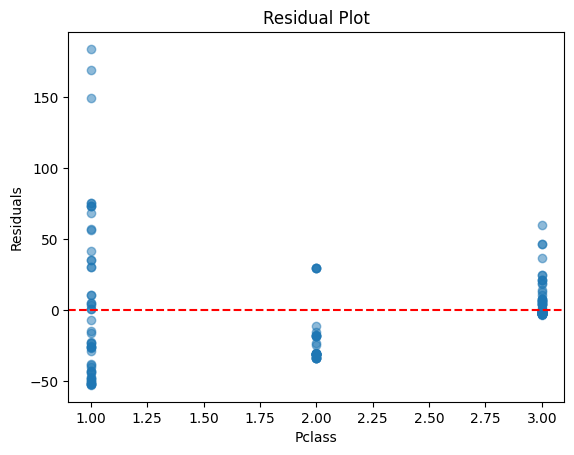

In [ ]:
residuals = y_te - pred_simple
plt.scatter(X_te, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Pclass');
plt.ylabel('Residuals');
plt.title('Residual Plot');
plt.show()

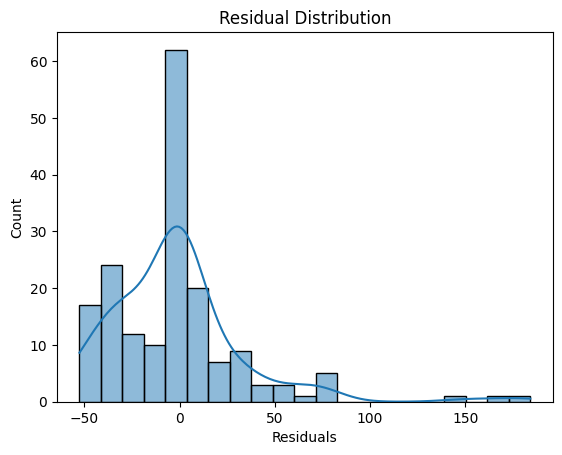

In [ ]:
sns.histplot(residuals, kde=True)
plt.xlabel('Residuals');
plt.title('Residual Distribution')
plt.show()


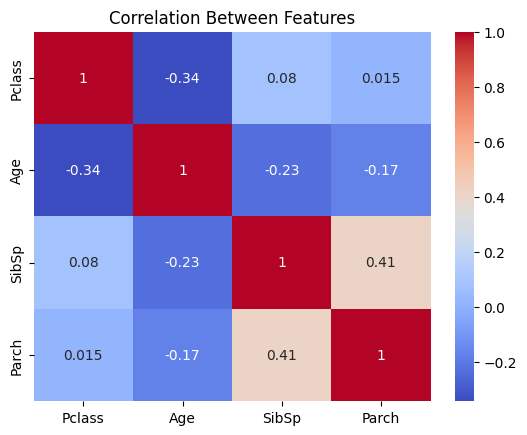

In [ ]:
sns.heatmap(X_multi.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Between Features')
plt.show()